# Proof of concept — do the hypotheses hold on the toy set?

This notebook does one thing: it **tests the hypotheses** of MIL-CREDA on one
toy scenario and states, for each one, **VALIDATED** or **NOT VALIDATED** by a
rule written down *before* any result is computed.

- **Scenario (fixed):** toy family `rollo` (CREDA's swiss roll, cut into bags),
  encoder `mlp` with BatchNorm. 3 classes, 81 bags of 30 instances per domain;
  the target is a perturbed, independent draw; target labels are read only to
  score.
- **Sources of the hypotheses:** proposal `research-concept-r38.md`; protocol
  `experiments-plan-experimental-mil-creda-sobre-balladeer-v55.md`, task-level
  hypothesis (lines 362/451/540) and the three contribution experiments K1
  (line 678), K2 (line 725) and K3 (line 763).
- **Evidence:** fresh seeds 10–39 and fresh toy draws. Earlier toy results
  (bound to r34) are **not** evidence here.

| Section | Hypothesis tested here |
|---|---|
| H-task | MIL-CREDA (global + local, TGL) beats the source-only floor on the target |
| K1 | Own attention gives less weight to contaminated instances than to clean ones, and more so than the own mechanism without consensus |
| K2 | A target bag lies closer to its own partner source bag than to the others, and more so with the local term than without it |
| K3 | Own mechanism > own without consensus; both terms > global only; both terms > local only |

## Where the repository is

In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()


## Tools

Everything that trains or measures comes from `MIL_CREDA_Benchmark.poc`, which
reuses the benchmark as it is: bags from `bags.build`, arms from `wiring`, the
phase helpers from `toy_run`, and the two training loops of the tutorial
`Toyset.ipynb` lifted into functions so each seed can run in its own process.

In [2]:
import hashlib
import json
import os
import time
from datetime import datetime, timezone

REPOSITORY = ROOT
SRC = str(REPOSITORY / "src")
import sys
sys.path.insert(0, SRC)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from MIL_CREDA_Benchmark import config, poc, toy_run

RESULTS = REPOSITORY / "MIL-CREDA" / "Results" / "PoC"
RESULTS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 4)
print("repository:", REPOSITORY)
print("revision:  ", config.REVISION)
print("scenario:  ", poc.FAMILY, "/", poc.BACKBONE, "(BatchNorm)")
print("scale:     ", poc.SCALE.name, "- epochs", poc.SCALE.epochs_1, "/", poc.SCALE.epochs_2,
      "- patience", poc.SCALE.patience_1, "-", poc.SCALE.points_per_domain, "points/domain")

repository: /Users/diego/Proyectos/MIL-CREDA/implementations/Domain_Adaptation
revision:   research-concept-r38.md
scenario:   rollo / mlp (BatchNorm)
scale:      full - epochs 100 / 100 - patience 30 - 4050 points/domain


## Pre-registration (written before any result cell)

**Unit of analysis.** One seed = one fresh toy draw (source and target), one
initialization and one sampling stream. Every contrast is **paired over
seeds**: all arms of a seed see the same draw, the same initialization and the
same batches.

**Seeds.** 10–39 (30 seeds) for every hypothesis. K3 rungs need about 22–30
seeds for power (L94); 30 covers it. Seeds are reduced only if the timing
forecast below exceeds 5 hours, and the reduction would be declared there.

**Test.** Wilcoxon signed-rank, one-sided in the hypothesis' direction, zero
differences dropped (`zero_method="wilcox"`), reported with the rank-biserial
correlation and the Hodges–Lehmann estimate with its Wilcoxon 95 % interval
(the protocol's reporting for every Wilcoxon test). **α = 0.05.** Holm within
each hypothesis' family of tests.

**Metric.** Target test accuracy (18 bags, 6 per class, so accuracy equals
balanced accuracy). Phase 1 keeps the best source-validation epoch; phase 2
keeps the epoch with the largest effective number of predicted classes on the
unlabelled target train role (`toy_run.effective_classes`, label-free). Both as
in the tutorial.

**Arms** (every arm uses the same hyperparameters, see deviations D3):

| Arm | What it is | Differs from TGL by |
|---|---|---|
| `TGL` | MIL-CREDA: own attention (relevance + consensus, γ = 0.863), global + local terms | — |
| `TG` | global term only | local term off |
| `TL` | local term only | global term off |
| `TGL-NC` | own mechanism **without consensus** | γ = 0 (phase 1 and 2) |
| source-only floor | the phase-1 model read on the target with θt = θs (no adaptation) | adaptation off |
| AdaBN | θt = θs with BatchNorm statistics re-estimated on the unlabelled target | information only, never a criterion |
| `abmil-published`, `abmil-gated`, `max`, `mean` | TGL with Eq. (15)/(16) swapped for a reference pooling | K1 references, no criterion |

`TGL`, `TG` and `TL` share **one phase-1 checkpoint** per seed (phase 1 has no
adaptation term) and run phase 2 from it with the same generator seed: same
steps, same source batches, same target draws, same epochs, same selection
rule. `TGL-NC` and the references train their own phase 1 (the aggregation
enters phase 1) from the same seed.

### The rules

| ID | Contrast (per seed) | Test | Pass rule |
|---|---|---|---|
| **H-task** | acc(TGL) − acc(source-only) | Wilcoxon, one-sided `>` | **VALIDATED** iff p < 0.05 |
| **K1a(r)** | own attention contrast c(TGL) > 0 | Wilcoxon one-sample, `>` | at each rate r ∈ {0.1, 0.2, 0.3} |
| **K1b(r)** | c(TGL) − c(TGL-NC) > 0 | Wilcoxon paired, `>` | at each rate r |
| **K1** | the 6 tests above | Holm over 6 | **VALIDATED** iff all 6 Holm-adjusted p < 0.05 |
| **K2a** | partner separation s(TGL) > 0 | Wilcoxon one-sample, `>` | |
| **K2b** | s(TGL) − s(TG) > 0 | Wilcoxon paired, `>` | |
| **K2** | the 2 tests above | Holm over 2 | **VALIDATED** iff both Holm-adjusted p < 0.05 |
| **K3a** | acc(TGL) − acc(TGL-NC) | Wilcoxon paired, `>` | |
| **K3b** | acc(TGL) − acc(TG) | Wilcoxon paired, `>` | |
| **K3c** | acc(TGL) − acc(TL) | Wilcoxon paired, `>` | |
| **K3** | the 3 tests above | Holm over 3 | **VALIDATED** iff all 3 Holm-adjusted p < 0.05 |

**K1 measurement.** At rate r, `bags.build`'s own contamination seam replaces
`round(30 r)` instances of every train and eval bag of **both** domains with
points of one donor class (label kept). Each arm trains both phases on that
material. On the **target test bags**, read with θt, the per-bag contrast is
`m · (mean weight of clean instances − mean weight of contaminated
instances)`, in units of the uniform weight 1/m: 0 for uniform pooling,
positive when contaminated instances get less weight. Per seed: the mean over
the 18 test bags. The same contrast on the source test bags (θs) is reported
as support.

**K2 measurement.** Probe = the 18 target test bags. The partner of target bag
k of class c is source test bag k of class c: both are the same band of the
roll, because the two domains share one band permutation
(`toy_bags.construir`). Distance = ‖Ψ_a − Ψ_b‖ in the instance-kernel RKHS
(bag kernel, Eq. 18) at the model's frozen σ, source bags through θs and
target bags through θt. Per target bag: mean distance to the other source test
bags **of its class** minus the distance to its partner; per seed: the mean
over the probe. Also reported, without criterion: the separation against all
other source test bags, and the local term's own conditional mass on the
partner (Eq. 35; chance = 1/6).

In [3]:
PREREGISTRATION = {
    "writtenAt": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "scenario": {"family": poc.FAMILY, "backbone": poc.BACKBONE, "scale": poc.SCALE.name},
    "seeds": list(range(10, 40)),
    "contaminationRates": [0.1, 0.2, 0.3],
    "alpha": 0.05,
    "test": "Wilcoxon signed-rank, one-sided greater, zero_method=wilcox; "
            "rank-biserial; Hodges-Lehmann with Wilcoxon 95% CI",
    "hypotheses": {
        "H-task": {"contrast": "acc(TGL) - acc(sourceOnly)", "family": ["H-task"],
                   "rule": "VALIDATED iff p < alpha"},
        "K1": {"contrast": ["c(TGL) > 0 at each rate", "c(TGL) - c(TGL-NC) > 0 at each rate"],
               "family": "6 tests, Holm", "rule": "VALIDATED iff all 6 Holm-adjusted p < alpha"},
        "K2": {"contrast": ["s(TGL) > 0", "s(TGL) - s(TG) > 0"],
               "family": "2 tests, Holm", "rule": "VALIDATED iff both Holm-adjusted p < alpha"},
        "K3": {"contrast": ["acc(TGL)-acc(TGL-NC)", "acc(TGL)-acc(TG)", "acc(TGL)-acc(TL)"],
               "family": "3 tests, Holm", "rule": "VALIDATED iff all 3 Holm-adjusted p < alpha"},
    },
    "hyperparameters": poc.poc_hyper(),
    "sigmaMultiplier": poc.SIGMA_MULTIPLIER,
    "noisePairingToy": poc.NOISE_PAIRING_TOY,
}
text = json.dumps(PREREGISTRATION, indent=2, sort_keys=True)
(RESULTS / "preregistration.json").write_text(text + "\n")
print("pre-registration sha256:", hashlib.sha256(text.encode()).hexdigest())
print("written at:", PREREGISTRATION["writtenAt"], "- before any training cell below")

pre-registration sha256: effec51ba17f11ae4700dc72aab559ee8a2dd676af4777c329fdebf9fbd7db6e
written at: 2026-11-05T07:20:52+00:00 - before any training cell below


## Declared deviations from the protocol

- **D1 — unit.** The protocol's unit is the subject (EEG). The toy set has no
  subjects; the unit here is the seed (one fresh draw), and every contrast is
  paired over seeds.
- **D2 — K3 test.** The protocol uses a paired bootstrap by subject for K3;
  here, a paired Wilcoxon over seeds, with Holm over the three rungs as the
  protocol states.
- **D3 — hyperparameters.** No search runs here. All arms use the archived
  `rollo` search choice (`Results/Toyset/full/barrido.json`, `hp1`/`hp2`; search
  seeds 100–102, disjoint from 10–39): lr1 0.0153, wd1 6.3e-7, γ 0.863,
  τ_att 0.426, dim 64, σ multiplier 0.5, τ_local 0.275, lr2 0.00264, wd2 1.5e-6.
  The toyset's declared γ is 0, which would make "own" and "own without
  consensus" the same arm; the archived γ is what gives the consensus a value.
- **D4 — K1 contamination.** EEG "marked windows" (sample loss, bad contact)
  have no toy counterpart. The closest declared measurement is `bags.build`'s
  own contamination seam: instances of another class injected into a bag whose
  label is kept, i.e. instances that are atypical for their bag. The seam's
  ten-class donor pairing is bent, for the duration of the draw only, to the
  three-class cycle 0→1→2→0. The behavioural-event contrast of K1 has no toy
  counterpart and is not run. The contaminated arms are trained on
  contaminated material (the attention can only learn to down-weight what it
  has seen), at three rates.
- **D5 — K2 subjects.** A subject's "own source bag" is replaced by the source
  bag that covers the same band of the roll (shared band permutation,
  `toy_bags.py` lines 225–245): bag k of class c in both domains.
- **D6 — K2 without the local term.** The protocol's "MIL-CREDA without the
  local term" is the global-only arm `TG`, as in the protocol.
- **D7 — task hypothesis.** The protocol's task hypothesis also ranks
  MIL-CREDA among nine strategies on EEG; that half belongs to the full
  experiments. Here only "beats the source-only floor" is tested; AdaBN is
  information.
- **D8 — work per step.** `TG` and `TL` run the same steps, batches, target
  draws and epochs as `TGL`; an absent term is simply not computed.

## Configuration and timing forecast

One ladder seed (four arms) and one K1 job (six arms at one rate) are timed
first; the forecast for the whole battery follows. Jobs run in parallel worker
processes, one seed (or seed and rate) per job, one thread each; a job depends
only on its arguments, so the result does not depend on the worker count. The
timed seed is re-run inside the battery, which doubles as a reproducibility
check.

In [4]:
SEEDS = PREREGISTRATION["seeds"]
RATES = PREREGISTRATION["contaminationRates"]
WORKERS = max(1, min(6, (os.cpu_count() or 2) - 2))
BUDGET_HOURS = 5.0

torch.set_num_threads(1)
probe_ladder = poc.run_ladder_seed(SEEDS[0])
probe_k1 = poc.run_contamination_seed(SEEDS[0], RATES[1])
serial = len(SEEDS) * probe_ladder["seconds"] + len(SEEDS) * len(RATES) * probe_k1["seconds"]
forecast_h = serial / WORKERS / 3600
print(f"one ladder seed: {probe_ladder['seconds']:.1f} s   one K1 job: {probe_k1['seconds']:.1f} s")
print(f"jobs: {len(SEEDS)} ladder + {len(SEEDS) * len(RATES)} K1   workers: {WORKERS}")
print(f"forecast: {serial / 3600:.2f} h serial -> {forecast_h:.2f} h wall on {WORKERS} workers"
      f" (budget {BUDGET_HOURS} h)")
if serial / 3600 > BUDGET_HOURS and forecast_h > BUDGET_HOURS:
    raise RuntimeError("forecast exceeds the budget: reduce seeds and declare it here")
print("seeds kept: 10-39 (no reduction needed)")

one ladder seed: 32.9 s   one K1 job: 48.7 s
jobs: 30 ladder + 90 K1   workers: 6
forecast: 1.49 h serial -> 0.25 h wall on 6 workers (budget 5.0 h)
seeds kept: 10-39 (no reduction needed)


## Run the battery

In [5]:
start = time.perf_counter()
jobs = [("run_ladder_seed", (s,)) for s in SEEDS]
jobs += [("run_contamination_seed", (s, r)) for r in RATES for s in SEEDS]
outputs = poc.run_many(jobs, WORKERS, SRC)
LADDER = {o["seed"]: o for o in outputs[:len(SEEDS)]}
K1RUNS = {(o["rate"], o["seed"]): o for o in outputs[len(SEEDS):]}
BATTERY_SECONDS = time.perf_counter() - start

same_ladder = all(LADDER[SEEDS[0]]["arms"][a]["targetAccuracy"] == probe_ladder["arms"][a]["targetAccuracy"]
                  for a in probe_ladder["arms"])
same_k1 = all(K1RUNS[(RATES[1], SEEDS[0])]["arms"][a]["targetContrast"] == probe_k1["arms"][a]["targetContrast"]
              for a in probe_k1["arms"])
raw = {"preregistrationWrittenAt": PREREGISTRATION["writtenAt"],
       "batterySeconds": BATTERY_SECONDS, "workers": WORKERS,
       "ladder": [LADDER[s] for s in SEEDS],
       "contamination": [K1RUNS[(r, s)] for r in RATES for s in SEEDS],
       "probe": {"ladder": probe_ladder, "contamination": probe_k1}}
(RESULTS / "raw_results.json").write_text(json.dumps(raw, indent=1) + "\n")
print(f"battery: {len(jobs)} jobs in {BATTERY_SECONDS / 60:.1f} min on {WORKERS} workers")
print("timed seed reproduced inside the battery:", same_ladder and same_k1)
print("raw results:", RESULTS / "raw_results.json")

battery: 120 jobs in 24.5 min on 6 workers
timed seed reproduced inside the battery: True
raw results: /Users/diego/Proyectos/MIL-CREDA/implementations/Domain_Adaptation/MIL-CREDA/Results/PoC/raw_results.json


In [6]:
ALPHA = PREREGISTRATION["alpha"]
VERDICTS = {}


def test_row(name, result, adjusted=None):
    row = {"test": name, "n": result["n"], "non-zero": result["nonZero"],
           "W": result["statistic"], "p": result["p"]}
    if adjusted is not None:
        row["p (Holm)"] = adjusted
    row.update({"rank-biserial": result["rankBiserial"], "HL": result["hodgesLehmann"],
                "HL 95% CI": "[{:.4f}, {:.4f}]".format(*result["hodgesLehmannCI"])})
    return row


def summary_rows(columns):
    rows = []
    for name, values in columns.items():
        s = poc.summary(values)
        rows.append({"quantity": name, "mean": s["mean"], "sd": s["sd"],
                     "95% CI": "[{:.4f}, {:.4f}]".format(*s["ci95"]), "median": s["median"],
                     "n": s["n"]})
    return pd.DataFrame(rows).set_index("quantity")


def verdict(key, passed, line):
    VERDICTS[key] = {"verdict": "VALIDATED" if passed else "NOT VALIDATED", "evidence": line}
    display(Markdown(f"### Verdict {key}: **{VERDICTS[key]['verdict']}**\n\n{line}"))


def save(fig, name):
    fig.savefig(RESULTS / name, dpi=130, bbox_inches="tight")
    plt.show()


def arm_column(arm, key):
    return np.array([LADDER[s]["arms"][arm][key] for s in SEEDS])

print("analysis helpers ready: alpha =", ALPHA, "- verdicts are read only from the pre-registered rules")

analysis helpers ready: alpha = 0.05 - verdicts are read only from the pre-registered rules


## H-task — MIL-CREDA beats the source-only floor

**Tested:** per seed, target test accuracy of `TGL` against the source-only
floor (the same phase-1 model read on the target before any adaptation).
AdaBN is shown as information only.

In [7]:
tgl = arm_column("TGL", "targetAccuracy")
floor = arm_column("TGL", "sourceOnlyTargetAccuracy")
adabn = arm_column("TGL", "adabnTargetAccuracy")
per_seed_task = pd.DataFrame({"seed": SEEDS, "source-only": floor, "AdaBN (info)": adabn,
                              "TGL": tgl, "TGL - source-only": tgl - floor,
                              "source acc (TGL)": arm_column("TGL", "sourceAccuracy")}).set_index("seed")
display(per_seed_task)
display(summary_rows({"source-only": floor, "AdaBN (info)": adabn, "TGL": tgl,
                      "TGL - source-only": tgl - floor, "TGL - AdaBN (info)": tgl - adabn}))
task_test = poc.paired_wilcoxon(tgl, floor)
info_test = poc.paired_wilcoxon(tgl, adabn, alternative="two-sided")
display(pd.DataFrame([test_row("H-task: TGL > source-only", task_test),
                      test_row("info: TGL vs AdaBN (two-sided)", info_test)]).set_index("test"))

,source-only,AdaBN (info),TGL,TGL - source-only,source acc (TGL)
seed,,,,,
10,0.3333,1.0000,1.0000,0.6667,1.0000
11,0.4444,0.6667,0.7778,0.3333,0.8333
12,0.3333,0.7778,0.7778,0.4444,0.8889
13,0.3333,0.7222,0.8333,0.5000,0.8333
14,0.4444,0.9444,0.9444,0.5000,0.9444
15,0.3333,0.9444,0.8333,0.5000,1.0000
16,0.3333,0.7222,0.8333,0.5000,0.7778
17,0.3333,0.7778,0.9444,0.6111,1.0000
18,0.3333,1.0000,0.7222,0.3889,1.0000


,mean,sd,95% CI,median,n
quantity,,,,,
source-only,0.3519,0.0512,"[0.3327, 0.3710]",0.3333,30
AdaBN (info),0.7944,0.1178,"[0.7505, 0.8384]",0.7778,30
TGL,0.8389,0.1133,"[0.7966, 0.8812]",0.8333,30
TGL - source-only,0.4870,0.1327,"[0.4375, 0.5366]",0.5000,30
TGL - AdaBN (info),0.0444,0.1198,"[-0.0003, 0.0892]",0.0556,30


,n,non-zero,W,p,rank-biserial,HL,HL 95% CI
test,,,,,,,
H-task: TGL > source-only,30,30,465.0,8.2865e-07,1.0000,0.5000,"[0.4444, 0.5556]"
info: TGL vs AdaBN (two-sided),30,24,69.5,2.0912e-02,0.5367,0.0556,"[0.0000, 0.0833]"


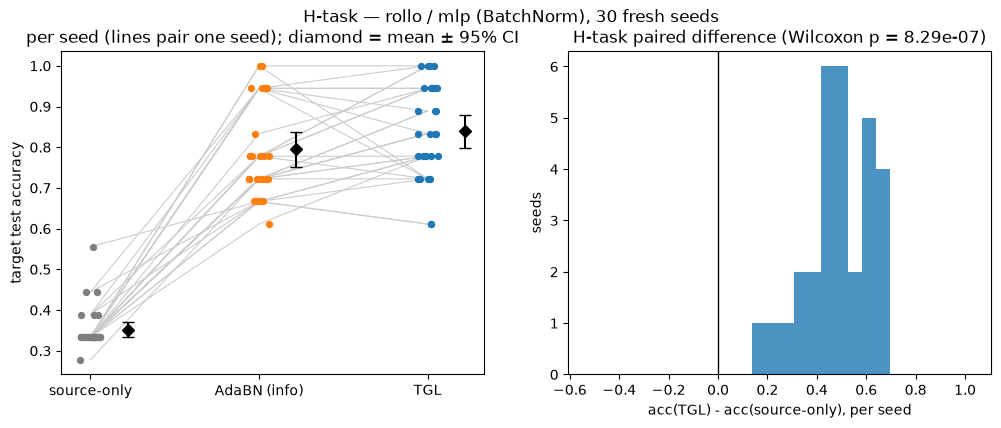

### Verdict H-task: **VALIDATED**

TGL 0.839 vs source-only 0.352 (mean target accuracy); W = 465.0, one-sided p = 8.29e-07, rank-biserial = 1.00, HL = 0.500. AdaBN (information only): 0.794.

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for i, s in enumerate(SEEDS):
    ax.plot([0, 1, 2], [floor[i], adabn[i], tgl[i]], color="0.8", lw=0.8, zorder=1)
jitter = np.random.default_rng(0).uniform(-0.06, 0.06, len(SEEDS))
for x, values, color, label in ((0, floor, "tab:gray", "source-only"), (1, adabn, "tab:orange", "AdaBN (info)"),
                                (2, tgl, "tab:blue", "TGL")):
    ax.scatter(x + jitter, values, color=color, s=18, zorder=2)
    ax.errorbar(x + 0.22, values.mean(), yerr=1.96 * values.std(ddof=1) / np.sqrt(len(values)),
                fmt="D", color="k", capsize=4, zorder=3)
ax.set_xticks([0, 1, 2], ["source-only", "AdaBN (info)", "TGL"])
ax.set_ylabel("target test accuracy")
ax.set_title("per seed (lines pair one seed); diamond = mean ± 95% CI")
ax = axes[1]
ax.hist(tgl - floor, bins=np.arange(-0.5, 1.06, 1 / 18) - 1 / 36, color="tab:blue", alpha=0.8)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("acc(TGL) - acc(source-only), per seed")
ax.set_ylabel("seeds")
ax.set_title(f"H-task paired difference (Wilcoxon p = {task_test['p']:.2e})")
fig.suptitle(f"H-task — rollo / mlp (BatchNorm), {len(SEEDS)} fresh seeds")
save(fig, "h_task.png")
verdict("H-task", task_test["p"] < ALPHA,
        f"TGL {tgl.mean():.3f} vs source-only {floor.mean():.3f} (mean target accuracy); "
        f"W = {task_test['statistic']:.1f}, one-sided p = {task_test['p']:.2e}, "
        f"rank-biserial = {task_test['rankBiserial']:.2f}, HL = {task_test['hodgesLehmann']:.3f}. "
        f"AdaBN (information only): {adabn.mean():.3f}.")

## K1 — own attention down-weights contaminated instances, more than without consensus

**Tested:** at each contamination rate, the attention contrast of `TGL` on the
target test bags (> 0 means contaminated instances get less weight) and its
paired difference with `TGL-NC`. References (`abmil-published`,
`abmil-gated`, `max`, `mean`) are trained and read the same way, without
criterion; `mean` is 0 by construction.

In [9]:
K1_ARMS = list(poc.K1_ARMS)


def k1_column(rate, arm, key="targetContrast"):
    return np.array([K1RUNS[(rate, s)]["arms"][arm][key] for s in SEEDS])


per_seed_k1 = pd.DataFrame(
    {(f"r={r}", arm): k1_column(r, arm) for r in RATES for arm in ("TGL", poc.NO_CONSENSUS)},
    index=pd.Index(SEEDS, name="seed"))
display(Markdown("**Per-seed target attention contrast** (units of 1/m; > 0 = contaminated get less weight)"))
display(per_seed_k1)

rows = []
for r in RATES:
    for arm in K1_ARMS:
        for side in ("target", "source"):
            values = k1_column(r, arm, f"{side}Contrast")
            s = poc.summary(values)
            rows.append({"rate": r, "arm": arm, "domain": side, "contrast mean": s["mean"],
                         "sd": s["sd"], "95% CI": "[{:.3f}, {:.3f}]".format(*s["ci95"]),
                         "contaminated mass": k1_column(r, arm, f"{side}ContaminatedMass").mean(),
                         "uniform mass": r,
                         "target acc": k1_column(r, arm, "targetAccuracy").mean()})
k1_summary = pd.DataFrame(rows).set_index(["rate", "arm", "domain"])
display(Markdown("**Summary over seeds, all arms** (`contaminated mass` = total weight on contaminated "
                 "instances per bag; uniform pooling puts `rate` there)"))
display(k1_summary)

k1_tests = []
for r in RATES:
    own, nc = k1_column(r, "TGL"), k1_column(r, poc.NO_CONSENSUS)
    k1_tests.append((f"K1a r={r}: c(TGL) > 0", poc.paired_wilcoxon(own)))
    k1_tests.append((f"K1b r={r}: c(TGL) > c(TGL-NC)", poc.paired_wilcoxon(own, nc)))
k1_adjusted = poc.holm([t["p"] for _, t in k1_tests])
display(pd.DataFrame([test_row(n, t, a) for (n, t), a in zip(k1_tests, k1_adjusted)]).set_index("test"))
ref_tests = [test_row(f"reference r={r}: c({arm}) > 0", poc.paired_wilcoxon(k1_column(r, arm)))
             for r in RATES for arm in poc.REFERENCE_MECHANISMS if arm != "mean"]
display(Markdown("**References, no criterion** (same one-sample test, unadjusted)"))
display(pd.DataFrame(ref_tests).set_index("test"))

**Per-seed target attention contrast** (units of 1/m; > 0 = contaminated get less weight)

r=0.1           r=0.2           r=0.3        
         TGL  TGL-NC     TGL  TGL-NC     TGL  TGL-NC
seed                                                
10   -0.4896 -0.7801  0.1719 -0.0355  0.0002 -0.0947
11    0.0665 -0.5334  0.3421 -0.3139  0.2739  0.0800
12    0.1443 -0.3691  0.0095 -0.0917  0.2386  0.0016
13    0.1251 -0.2014  0.0380 -0.1545  0.2676 -0.1660
14   -0.3642 -0.6508 -0.0146 -0.0093  0.2593 -0.2370
15    0.0253 -0.8079  0.1517 -0.1318  0.3329  0.0865
16    0.0986 -0.0188  0.0019 -0.2250  0.1578  0.0631
17    0.0569 -0.0295  0.1193 -0.2443  0.2715 -0.1790
18    0.1895 -0.1534  0.2910 -0.3267  0.3122 -0.0953
19    0.0915 -0.5251 -0.6357 -0.5598  0.2069 -0.0625
20    0.0556 -0.2354  0.2232 -0.0797  0.0892  0.0472
21    0.1028 -0.4748 -0.4117 -0.4917  0.2424 -0.1708
22    0.1500 -0.3366  0.0812 -0.0091  0.1319 -0.1041
23    0.0734 -0.3984 -0.0223 -0.0410  0.1897  0.0133
24    0.2544 -0.0500  0.3164 -0.0616  0.1703  0.0184
25    0.0563 -0.2076  0.3276  0.0739  0.2846 -0.0157
26   -0.0212 -0.0435  0.0353 -0.1838  0.2452 -0.4409
27   -0.3191 -0.4334  0.0120 -0.0341  0.2897  0.0030
28   -0.1687 -0.1250  0.1462  0.0060  0.1676 -0.0394
29   -0.7492 -0.0616 -0.0294 -0.2149  0.0742 -0.1162
30   -0.6931 -0.0505  0.1786 -0.9322  0.3287 -0.1794
31    0.0601 -0.3431  0.3344 -0.0584  0.0894  0.0333
32    0.0469 -0.0273  0.2283 -0.1503  0.2952 -0.1556
33   -0.0338 -0.1817  0.1457 -0.0059  0.0777 -0.0184
34    0.0482  0.0804  0.1803  0.0172  0.2378 -0.1523
35   -0.1007 -0.0180  0.1873 -0.2932  0.1007  0.0089
36   -0.4692  0.0019 -0.1084 -0.3977  0.0355 -0.0729
37   -0.0315 -0.3530 -0.1090 -0.2117  0.1678  0.0311
38   -0.5689 -0.0445  0.2489 -0.0390  0.3262 -0.5417
39    0.3013 -0.5584 -0.1536 -0.0301  0.1173 -0.0008

**Summary over seeds, all arms** (`contaminated mass` = total weight on contaminated instances per bag; uniform pooling puts `rate` there)

contrast mean      sd            95% CI  \
rate arm             domain                                            
0.1  TGL             target        -0.0688  0.2795   [-0.173, 0.036]   
                     source         0.1510  0.3536    [0.019, 0.283]   
     TGL-NC          target        -0.2643  0.2462  [-0.356, -0.172]   
                     source        -0.4052  0.3390  [-0.532, -0.279]   
     abmil-published target        -2.3982  1.9080  [-3.111, -1.686]   
                     source        -2.7131  1.3590  [-3.221, -2.206]   
     abmil-gated     target        -2.0531  1.8728  [-2.752, -1.354]   
                     source        -2.2391  1.5693  [-2.825, -1.653]   
     max             target        -3.5185  1.5612  [-4.101, -2.936]   
                     source        -3.8683  1.8192  [-4.548, -3.189]   
     mean            target         0.0000  0.0000    [0.000, 0.000]   
                     source         0.0000  0.0000    [0.000, 0.000]   
0.2  TGL             target         0.0762  0.2159   [-0.004, 0.157]   
                     source         0.2496  0.2522    [0.155, 0.344]   
     TGL-NC          target        -0.1743  0.2113  [-0.253, -0.095]   
                     source        -0.2411  0.2507  [-0.335, -0.148]   
     abmil-published target        -1.0217  0.8736  [-1.348, -0.696]   
                     source        -1.1876  0.8011  [-1.487, -0.888]   
     abmil-gated     target        -1.0176  0.6907  [-1.276, -0.760]   
                     source        -1.2439  0.7900  [-1.539, -0.949]   
     max             target        -1.4815  0.6234  [-1.714, -1.249]   
                     source        -1.6551  0.7379  [-1.931, -1.380]   
     mean            target         0.0000  0.0000    [0.000, 0.000]   
                     source         0.0000  0.0000    [0.000, 0.000]   
0.3  TGL             target         0.1994  0.0949    [0.164, 0.235]   
                     source         0.3932  0.1025    [0.355, 0.431]   
     TGL-NC          target        -0.0819  0.1424  [-0.135, -0.029]   
                     source        -0.1074  0.1404  [-0.160, -0.055]   
     abmil-published target        -0.9513  0.4709  [-1.127, -0.775]   
                     source        -1.0393  0.5090  [-1.229, -0.849]   
     abmil-gated     target        -0.6715  0.5084  [-0.861, -0.482]   
                     source        -0.7689  0.6060  [-0.995, -0.543]   
     max             target        -0.9347  0.5768  [-1.150, -0.719]   
                     source        -0.9524  0.6017  [-1.177, -0.728]   
     mean            target         0.0000  0.0000    [0.000, 0.000]   
                     source         0.0000  0.0000    [0.000, 0.000]   

                             contaminated mass  uniform mass  target acc  
rate arm             domain                                               
0.1  TGL             target             0.1062           0.1      0.8093  
                     source             0.0864           0.1      0.8093  
     TGL-NC          target             0.1238           0.1      0.8852  
                     source             0.1365           0.1      0.8852  
     abmil-published target             0.3158           0.1      0.5685  
                     source             0.3442           0.1      0.5685  
     abmil-gated     target             0.2848           0.1      0.6778  
                     source             0.3015           0.1      0.6778  
     max             target             0.4167           0.1      0.5352  
                     source             0.4481           0.1      0.5352  
     mean            target             0.1000           0.1      0.8630  
                     source             0.1000           0.1      0.8630  
0.2  TGL             target             0.1878           0.2      0.8037  
                     source             0.1601           0.2      0.8037  
     TGL-NC          target             0.2279           0.2      0.8185  
                 

,n,non-zero,W,p,p (Holm),rank-biserial,HL,HL 95% CI
test,,,,,,,,
K1a r=0.1: c(TGL) > 0,30,30,233.0,5.0000e-01,5.0000e-01,0.0022,0.0010,"[-0.1765, 0.0665]"
K1b r=0.1: c(TGL) > c(TGL-NC),30,30,358.0,4.3527e-03,1.3058e-02,0.5398,0.2204,"[0.0804, 0.3537]"
K1a r=0.2: c(TGL) > 0,30,30,354.0,5.6515e-03,1.3058e-02,0.5226,0.0984,"[0.0224, 0.1647]"
K1b r=0.2: c(TGL) > c(TGL-NC),30,30,451.0,1.0245e-07,4.0978e-07,0.9398,0.2233,"[0.1533, 0.2989]"
K1a r=0.3: c(TGL) > 0,30,30,465.0,9.3132e-10,5.5879e-09,1.0000,0.2028,"[0.1644, 0.2419]"
K1b r=0.3: c(TGL) > c(TGL-NC),30,30,465.0,9.3132e-10,5.5879e-09,1.0000,0.2642,"[0.1907, 0.3384]"


**References, no criterion** (same one-sample test, unadjusted)

,n,non-zero,W,p,rank-biserial,HL,HL 95% CI
test,,,,,,,
reference r=0.1: c(abmil-published) > 0,30,30,16.0,1.0,-0.9312,-2.4260,"[-3.0979, -1.5324]"
reference r=0.1: c(abmil-gated) > 0,30,30,16.0,1.0,-0.9312,-2.0416,"[-2.7560, -1.2470]"
reference r=0.1: c(max) > 0,30,30,0.0,1.0,-1.0000,-3.5185,"[-4.1358, -2.9012]"
reference r=0.2: c(abmil-published) > 0,30,30,30.0,1.0,-0.8710,-0.9863,"[-1.3689, -0.6666]"
reference r=0.2: c(abmil-gated) > 0,30,30,1.0,1.0,-0.9957,-1.0151,"[-1.2704, -0.7128]"
reference r=0.2: c(max) > 0,30,30,0.0,1.0,-1.0000,-1.5278,"[-1.7014, -1.1806]"
reference r=0.3: c(abmil-published) > 0,30,30,1.0,1.0,-0.9957,-0.9625,"[-1.1359, -0.7696]"
reference r=0.3: c(abmil-gated) > 0,30,30,12.0,1.0,-0.9484,-0.6688,"[-0.8629, -0.4681]"
reference r=0.3: c(max) > 0,30,30,0.0,1.0,-1.0000,-0.9524,"[-1.0847, -0.6878]"


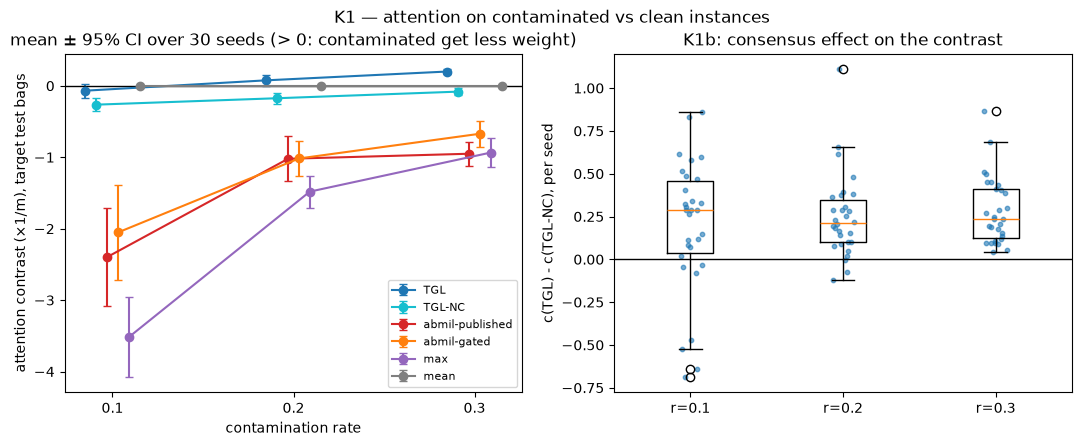

### Verdict K1: **NOT VALIDATED**

K1a r=0.1: c(TGL) > 0: p_Holm = 5.00e-01; K1b r=0.1: c(TGL) > c(TGL-NC): p_Holm = 1.31e-02; K1a r=0.2: c(TGL) > 0: p_Holm = 1.31e-02; K1b r=0.2: c(TGL) > c(TGL-NC): p_Holm = 4.10e-07; K1a r=0.3: c(TGL) > 0: p_Holm = 5.59e-09; K1b r=0.3: c(TGL) > c(TGL-NC): p_Holm = 5.59e-09. Mean contrasts c(TGL) / c(TGL-NC): r=0.1: -0.069 / -0.264, r=0.2: 0.076 / -0.174, r=0.3: 0.199 / -0.082.

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
colors = {"TGL": "tab:blue", poc.NO_CONSENSUS: "tab:cyan", "abmil-published": "tab:red",
          "abmil-gated": "tab:orange", "max": "tab:purple", "mean": "tab:gray"}
for k, arm in enumerate(K1_ARMS):
    means = [k1_column(r, arm).mean() for r in RATES]
    half = [1.96 * k1_column(r, arm).std(ddof=1) / np.sqrt(len(SEEDS)) for r in RATES]
    ax.errorbar(np.array(RATES) + (k - 2.5) * 0.006, means, yerr=half, marker="o", capsize=3,
                color=colors[arm], label=arm)
ax.axhline(0, color="k", lw=1)
ax.set_xticks(RATES)
ax.set_xlabel("contamination rate")
ax.set_ylabel("attention contrast (×1/m), target test bags")
ax.set_title(f"mean ± 95% CI over {len(SEEDS)} seeds (> 0: contaminated get less weight)")
ax.legend(fontsize=8)
ax = axes[1]
data = [k1_column(r, "TGL") - k1_column(r, poc.NO_CONSENSUS) for r in RATES]
ax.boxplot(data, tick_labels=[f"r={r}" for r in RATES])
for i, d in enumerate(data, 1):
    ax.scatter(np.full(len(d), i) + np.random.default_rng(i).uniform(-0.08, 0.08, len(d)), d, s=10,
               color="tab:blue", alpha=0.6)
ax.axhline(0, color="k", lw=1)
ax.set_ylabel("c(TGL) - c(TGL-NC), per seed")
ax.set_title("K1b: consensus effect on the contrast")
fig.suptitle("K1 — attention on contaminated vs clean instances")
save(fig, "k1_attention.png")
k1_pass = all(a < ALPHA for a in k1_adjusted)
verdict("K1", k1_pass,
        "; ".join(f"{n}: p_Holm = {a:.2e}" for (n, _), a in zip(k1_tests, k1_adjusted))
        + ". Mean contrasts c(TGL) / c(TGL-NC): "
        + ", ".join(f"r={r}: {k1_column(r, 'TGL').mean():.3f} / {k1_column(r, poc.NO_CONSENSUS).mean():.3f}"
                    for r in RATES) + ".")

## K2 — the target bag lies closer to its own partner, more with the local term

**Tested:** per seed, the within-class partner separation of `TGL` (> 0) and
its paired difference with the global-only arm `TG`. Reported without
criterion: the separation across all classes, the local term's conditional
mass on the partner (chance 1/6), and the source-only floor.

In [11]:
def k2(arm, key):
    if arm == "source-only":
        return np.array([LADDER[s]["sourceOnlyPartner"][key] for s in SEEDS])
    return np.array([LADDER[s]["arms"][arm]["partner"][key] for s in SEEDS])


sep_tgl, sep_tg = k2("TGL", "separationWithin"), k2("TG", "separationWithin")
per_seed_k2 = pd.DataFrame({"seed": SEEDS, "s(TGL)": sep_tgl, "s(TG)": sep_tg,
                            "s(TGL) - s(TG)": sep_tgl - sep_tg,
                            "s(source-only)": k2("source-only", "separationWithin"),
                            "partner mass TGL": k2("TGL", "partnerMass"),
                            "partner mass TG": k2("TG", "partnerMass")}).set_index("seed")
display(per_seed_k2)
display(summary_rows({
    "s within class, TGL": sep_tgl, "s within class, TG": sep_tg,
    "s within class, source-only": k2("source-only", "separationWithin"),
    "s(TGL) - s(TG)": sep_tgl - sep_tg,
    "s across classes, TGL (info)": k2("TGL", "separationAcross"),
    "s across classes, TG (info)": k2("TG", "separationAcross"),
    "distance to own partner, TGL": k2("TGL", "ownDistance"),
    "distance to own partner, TG": k2("TG", "ownDistance"),
    "partner mass, TGL (chance 1/6)": k2("TGL", "partnerMass"),
    "partner mass, TG (chance 1/6)": k2("TG", "partnerMass")}))
k2_tests = [("K2a: s(TGL) > 0", poc.paired_wilcoxon(sep_tgl)),
            ("K2b: s(TGL) > s(TG)", poc.paired_wilcoxon(sep_tgl, sep_tg))]
k2_adjusted = poc.holm([t["p"] for _, t in k2_tests])
info = [("info: partner mass TGL > 1/6", poc.paired_wilcoxon(k2("TGL", "partnerMass") - 1 / 6))]
display(pd.DataFrame([test_row(n, t, a) for (n, t), a in zip(k2_tests, k2_adjusted)]
                     + [test_row(n, t) for n, t in info]).set_index("test"))

,s(TGL),s(TG),s(TGL) - s(TG),s(source-only),partner mass TGL,partner mass TG
seed,,,,,,
10,0.0078,0.0549,-0.0471,8.2666e-04,0.1686,0.1858
11,0.0091,-0.0065,0.0156,5.1245e-04,0.1694,0.1640
12,0.0363,0.0589,-0.0225,2.0076e-04,0.1766,0.1857
13,0.0008,0.0378,-0.0370,1.2557e-03,0.1668,0.1822
14,0.0353,0.0325,0.0029,-1.3715e-04,0.1803,0.1796
15,0.0466,0.0182,0.0284,-3.1300e-04,0.1821,0.1739
16,0.0436,0.0441,-0.0005,-1.3284e-03,0.1852,0.1831
17,0.0114,0.0051,0.0063,2.4459e-04,0.1703,0.1693
18,0.0032,0.0083,-0.0051,-2.1191e-04,0.1678,0.1698


,mean,sd,95% CI,median,n
quantity,,,,,
"s within class, TGL",0.0332,0.0318,"[0.0213, 0.0451]",0.0256,30
"s within class, TG",0.0388,0.0328,"[0.0266, 0.0511]",0.0373,30
"s within class, source-only",-0.0005,0.0028,"[-0.0016, 0.0006]",-0.0002,30
s(TGL) - s(TG),-0.0056,0.0398,"[-0.0205, 0.0092]",-0.0040,30
"s across classes, TGL (info)",0.0618,0.0560,"[0.0409, 0.0827]",0.0535,30
"s across classes, TG (info)",0.0711,0.0502,"[0.0523, 0.0898]",0.0564,30
"distance to own partner, TGL",0.6634,0.0443,"[0.6468, 0.6799]",0.6702,30
"distance to own partner, TG",0.7531,0.0576,"[0.7316, 0.7746]",0.7551,30
"partner mass, TGL (chance 1/6)",0.1779,0.0112,"[0.1737, 0.1820]",0.1751,30


,n,non-zero,W,p,p (Holm),rank-biserial,HL,HL 95% CI
test,,,,,,,,
K2a: s(TGL) > 0,30,30,464.0,1.8626e-09,3.7253e-09,0.9957,0.0283,"[0.0186, 0.0410]"
K2b: s(TGL) > s(TG),30,30,186.0,8.3063e-01,8.3063e-01,-0.2000,-0.0056,"[-0.0209, 0.0078]"
info: partner mass TGL > 1/6,30,30,458.0,1.7695e-08,NaN,0.9699,0.0099,"[0.0060, 0.0142]"


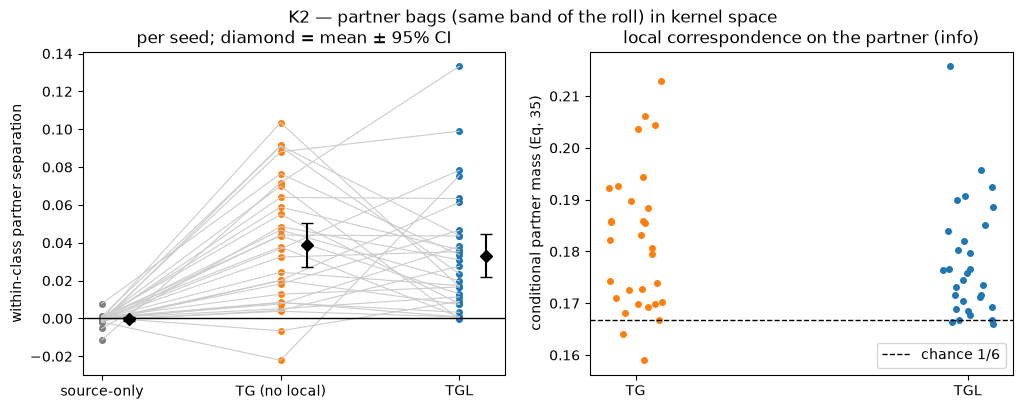

### Verdict K2: **NOT VALIDATED**

K2a: s(TGL) > 0: p_Holm = 3.73e-09; K2b: s(TGL) > s(TG): p_Holm = 8.31e-01. Mean separation TGL 0.0332, TG 0.0388; partner mass TGL 0.178 (chance 0.167).

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for i in range(len(SEEDS)):
    ax.plot([0, 1, 2], [k2("source-only", "separationWithin")[i], sep_tg[i], sep_tgl[i]], color="0.8", lw=0.8)
for x, values, color, label in ((0, k2("source-only", "separationWithin"), "tab:gray", "source-only"),
                                (1, sep_tg, "tab:orange", "TG"), (2, sep_tgl, "tab:blue", "TGL")):
    ax.scatter(np.full(len(values), x), values, color=color, s=16)
    ax.errorbar(x + 0.15, values.mean(), yerr=1.96 * values.std(ddof=1) / np.sqrt(len(values)),
                fmt="D", color="k", capsize=4)
ax.axhline(0, color="k", lw=1)
ax.set_xticks([0, 1, 2], ["source-only", "TG (no local)", "TGL"])
ax.set_ylabel("within-class partner separation")
ax.set_title("per seed; diamond = mean ± 95% CI")
ax = axes[1]
for x, arm, color in ((0, "TG", "tab:orange"), (1, "TGL", "tab:blue")):
    values = k2(arm, "partnerMass")
    ax.scatter(np.full(len(values), x) + np.random.default_rng(x).uniform(-0.08, 0.08, len(values)),
               values, color=color, s=16)
ax.axhline(1 / 6, color="k", ls="--", lw=1, label="chance 1/6")
ax.set_xticks([0, 1], ["TG", "TGL"])
ax.set_ylabel("conditional partner mass (Eq. 35)")
ax.set_title("local correspondence on the partner (info)")
ax.legend()
fig.suptitle("K2 — partner bags (same band of the roll) in kernel space")
save(fig, "k2_partners.png")
k2_pass = all(a < ALPHA for a in k2_adjusted)
verdict("K2", k2_pass,
        "; ".join(f"{n}: p_Holm = {a:.2e}" for (n, _), a in zip(k2_tests, k2_adjusted))
        + f". Mean separation TGL {sep_tgl.mean():.4f}, TG {sep_tg.mean():.4f}; "
        f"partner mass TGL {k2('TGL', 'partnerMass').mean():.3f} (chance {1 / 6:.3f}).")

## K3 — the ladder: each rung differs from TGL by one thing

**Tested:** per seed, target test accuracy of `TGL` against `TGL-NC` (the
consensus), against `TG` (the local term) and against `TL` (the global term).

In [13]:
rungs = {"TGL": tgl, "TGL-NC": arm_column(poc.NO_CONSENSUS, "targetAccuracy"),
         "TG": arm_column("TG", "targetAccuracy"), "TL": arm_column("TL", "targetAccuracy")}
per_seed_k3 = pd.DataFrame({"seed": SEEDS, **rungs,
                            "TGL - TGL-NC": tgl - rungs["TGL-NC"], "TGL - TG": tgl - rungs["TG"],
                            "TGL - TL": tgl - rungs["TL"]}).set_index("seed")
display(per_seed_k3)
display(summary_rows({**rungs, "TGL - TGL-NC": tgl - rungs["TGL-NC"], "TGL - TG": tgl - rungs["TG"],
                      "TGL - TL": tgl - rungs["TL"],
                      "source-only (shared phase 1)": floor,
                      "source-only (TGL-NC phase 1)": arm_column(poc.NO_CONSENSUS, "sourceOnlyTargetAccuracy")}))
k3_tests = [("K3a: TGL > TGL-NC", poc.paired_wilcoxon(tgl, rungs["TGL-NC"])),
            ("K3b: TGL > TG", poc.paired_wilcoxon(tgl, rungs["TG"])),
            ("K3c: TGL > TL", poc.paired_wilcoxon(tgl, rungs["TL"]))]
k3_adjusted = poc.holm([t["p"] for _, t in k3_tests])
display(pd.DataFrame([test_row(n, t, a) for (n, t), a in zip(k3_tests, k3_adjusted)]).set_index("test"))

,TGL,TGL-NC,TG,TL,TGL - TGL-NC,TGL - TG,TGL - TL
seed,,,,,,,
10,1.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000
11,0.7778,0.6111,0.7222,0.8333,0.1667,0.0556,-0.0556
12,0.7778,0.6667,0.7778,0.7778,0.1111,0.0000,0.0000
13,0.8333,0.7778,0.8333,0.7778,0.0556,0.0000,0.0556
14,0.9444,0.9444,0.6667,0.8889,0.0000,0.2778,0.0556
15,0.8333,1.0000,0.8889,0.8889,-0.1667,-0.0556,-0.0556
16,0.8333,0.9444,0.6667,0.8333,-0.1111,0.1667,0.0000
17,0.9444,0.8889,1.0000,0.9444,0.0556,-0.0556,0.0000
18,0.7222,0.9444,0.9444,0.8889,-0.2222,-0.2222,-0.1667


,mean,sd,95% CI,median,n
quantity,,,,,
TGL,0.8389,0.1133,"[0.7966, 0.8812]",0.8333,30
TGL-NC,0.8519,0.1526,"[0.7949, 0.9088]",0.8889,30
TG,0.8259,0.1359,"[0.7752, 0.8767]",0.8333,30
TL,0.8463,0.1464,"[0.7916, 0.9010]",0.8889,30
TGL - TGL-NC,-0.0130,0.1773,"[-0.0792, 0.0532]",0.0000,30
TGL - TG,0.0130,0.1039,"[-0.0258, 0.0517]",0.0000,30
TGL - TL,-0.0074,0.1192,"[-0.0519, 0.0371]",0.0000,30
source-only (shared phase 1),0.3519,0.0512,"[0.3327, 0.3710]",0.3333,30
source-only (TGL-NC phase 1),0.3648,0.0631,"[0.3413, 0.3884]",0.3333,30


,n,non-zero,W,p,p (Holm),rank-biserial,HL,HL 95% CI
test,,,,,,,,
K3a: TGL > TGL-NC,30,21,80.0,0.8931,1.0000,-0.3074,-0.0278,"[-0.0833, 0.0278]"
K3b: TGL > TG,30,20,118.5,0.3045,0.9134,0.1286,0.0000,"[-0.0278, 0.0278]"
K3c: TGL > TL,30,22,92.5,0.8711,1.0000,-0.2688,-0.0278,"[-0.0556, 0.0000]"


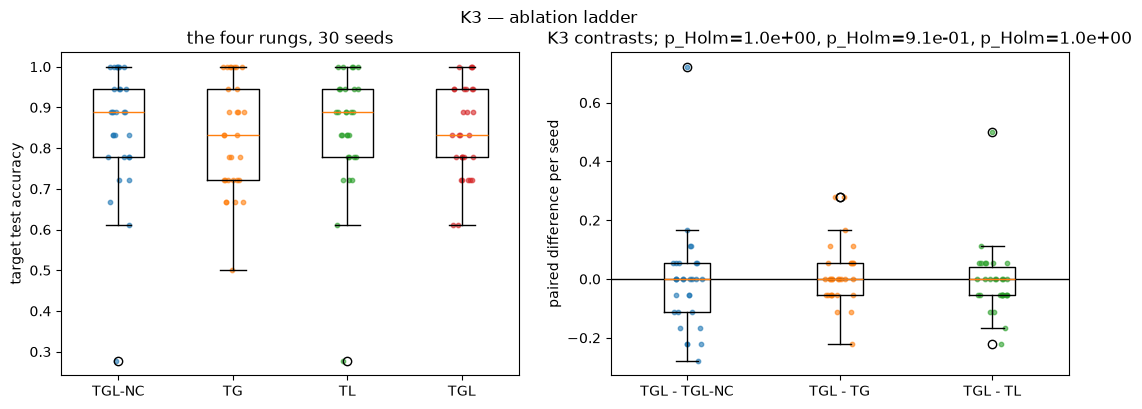

### Verdict K3: **NOT VALIDATED**

K3a: TGL > TGL-NC: mean diff -0.013, HL -0.028, p_Holm = 1.00e+00; K3b: TGL > TG: mean diff +0.013, HL +0.000, p_Holm = 9.13e-01; K3c: TGL > TL: mean diff -0.007, HL -0.028, p_Holm = 1.00e+00.

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
names = ["TGL-NC", "TG", "TL", "TGL"]
ax.boxplot([rungs[n] for n in names], tick_labels=names)
for i, n in enumerate(names, 1):
    ax.scatter(np.full(len(SEEDS), i) + np.random.default_rng(i).uniform(-0.1, 0.1, len(SEEDS)),
               rungs[n], s=10, alpha=0.6)
ax.set_ylabel("target test accuracy")
ax.set_title(f"the four rungs, {len(SEEDS)} seeds")
ax = axes[1]
diffs = [tgl - rungs[n] for n in ("TGL-NC", "TG", "TL")]
ax.boxplot(diffs, tick_labels=["TGL - TGL-NC", "TGL - TG", "TGL - TL"])
for i, d in enumerate(diffs, 1):
    ax.scatter(np.full(len(d), i) + np.random.default_rng(10 + i).uniform(-0.1, 0.1, len(d)), d, s=10, alpha=0.6)
ax.axhline(0, color="k", lw=1)
ax.set_ylabel("paired difference per seed")
ax.set_title("K3 contrasts; " + ", ".join(f"p_Holm={a:.1e}" for a in k3_adjusted))
fig.suptitle("K3 — ablation ladder")
save(fig, "k3_ladder.png")
k3_pass = all(a < ALPHA for a in k3_adjusted)
verdict("K3", k3_pass,
        "; ".join(f"{n}: mean diff {np.mean(tgl - rungs[other]):+.3f}, HL {t['hodgesLehmann']:+.3f}, "
                  f"p_Holm = {a:.2e}"
                  for ((n, t), a), other in zip(zip(k3_tests, k3_adjusted), ("TGL-NC", "TG", "TL")))
        + ".")

## Summary of all hypotheses

In [15]:
rows = [
    {"hypothesis": "H-task", "rule": "Wilcoxon TGL > source-only, p < 0.05",
     "key numbers": f"TGL {tgl.mean():.3f} vs floor {floor.mean():.3f}; p = {task_test['p']:.1e}"},
    {"hypothesis": "K1", "rule": "6 tests (K1a, K1b x 3 rates), all Holm p < 0.05",
     "key numbers": ", ".join(f"r={r}: c {k1_column(r, 'TGL').mean():.2f} vs NC {k1_column(r, poc.NO_CONSENSUS).mean():.2f}"
                              for r in RATES) + f"; max p_Holm = {max(k1_adjusted):.1e}"},
    {"hypothesis": "K2", "rule": "s(TGL) > 0 and s(TGL) > s(TG), both Holm p < 0.05",
     "key numbers": f"s TGL {sep_tgl.mean():.4f}, TG {sep_tg.mean():.4f}; p_Holm = "
                    + ", ".join(f"{a:.1e}" for a in k2_adjusted)},
    {"hypothesis": "K3", "rule": "TGL > TGL-NC, TG, TL, all Holm p < 0.05",
     "key numbers": ", ".join(f"{n} {rungs[n].mean():.3f}" for n in names) + "; p_Holm = "
                    + ", ".join(f"{a:.1e}" for a in k3_adjusted)},
]
final = pd.DataFrame(rows).set_index("hypothesis")
final["verdict"] = [VERDICTS[h]["verdict"] for h in final.index]
display(final)
report = {"preregistration": PREREGISTRATION, "verdicts": VERDICTS,
          "tests": {"H-task": task_test, "H-task-info-adabn": info_test,
                    "K1": [{"test": n, **t, "pHolm": a} for (n, t), a in zip(k1_tests, k1_adjusted)],
                    "K2": [{"test": n, **t, "pHolm": a} for (n, t), a in zip(k2_tests, k2_adjusted)],
                    "K3": [{"test": n, **t, "pHolm": a} for (n, t), a in zip(k3_tests, k3_adjusted)]},
          "batterySeconds": BATTERY_SECONDS, "workers": WORKERS}
(RESULTS / "verdicts.json").write_text(json.dumps(report, indent=2, default=float) + "\n")
print("written:", sorted(p.name for p in RESULTS.iterdir()))

,rule,key numbers,verdict
hypothesis,,,
H-task,"Wilcoxon TGL > source-only, p < 0.05",TGL 0.839 vs floor 0.352; p = 8.3e-07,VALIDATED
K1,"6 tests (K1a, K1b x 3 rates), all Holm p < 0.05","r=0.1: c -0.07 vs NC -0.26, r=0.2: c 0.08 vs N...",NOT VALIDATED
K2,"s(TGL) > 0 and s(TGL) > s(TG), both Holm p < 0.05","s TGL 0.0332, TG 0.0388; p_Holm = 3.7e-09, 8.3...",NOT VALIDATED
K3,"TGL > TGL-NC, TG, TL, all Holm p < 0.05","TGL-NC 0.852, TG 0.826, TL 0.846, TGL 0.839; p...",NOT VALIDATED


written: ['h_task.png', 'k1_attention.png', 'k2_partners.png', 'k3_ladder.png', 'preregistration.json', 'raw_results.json', 'verdicts.json']
